# LightGBM and XGBoost

Run after `notebooks/05_machine_learning/baselines/logistic_random_forest.ipynb` to also generate the four-model comparison. The complete training code is in notebook cells.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Libraries and inputs

Use the same dataset, predictors and split manifest as Logistic Regression / Random Forest.

In [2]:
from lightgbm import LGBMClassifier

from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, precision_recall_curve, roc_auc_score

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder

INPUTS = ['data/processed/research_data_weather_price_holiday_assume_utc.csv', 'docs/predictor_list.csv', 'data/ml_preparation/split_manifest.csv']

EXPECTED = {'train': (57449, 3720), 'validation_a': (7661, 387), 'validation_b': (3115, 180), 'test': (9445, 504)}


## Load and audit splits

Check unique order IDs, valid labels and the expected sample sizes. B/Test are not used for model selection.

In [3]:
features = pd.read_csv(ROOT / INPUTS[1]).feature.tolist()

assert len(features) == len(set(features)) == 21

df = pd.read_csv(ROOT / INPUTS[0])

manifest = pd.read_csv(ROOT / INPUTS[2])

assert df.order_id.is_unique and manifest.order_id.is_unique

selected = manifest.loc[manifest.split.isin(EXPECTED), ['order_id', 'split']]

data = selected.merge(df, on='order_id', how='left', validate='one_to_one', indicator=True)

assert data._merge.eq('both').all()

audit = []

for split, (n, positives) in EXPECTED.items():
    z = data.loc[data.split.eq(split)]
    assert len(z) == n and z.is_late.notna().all()
    assert z.is_late.isin([0, 1]).all() and int(z.is_late.sum()) == positives
    audit.append(dict(split=split, n=n, late=positives))
display(pd.DataFrame(audit))


,split,n,late
0,train,57449,3720
1,validation_a,7661,387
2,validation_b,3115,180
3,test,9445,504


## Prepare features

Imputation and one-hot encoding are fitted on Train only; tree models use no scaling.

In [4]:
train = data.loc[data.split.eq('train')].copy()

val = data.loc[data.split.eq('validation_a')].copy()

cat = ['customer_state', 'purchase_weekday']

num = [f for f in features if f not in cat]

for z in (train, val):
    for c in cat:
        z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan)
    for c in num:
        z[c] = pd.to_numeric(z[c], errors='raise').replace([np.inf, -np.inf], np.nan)

assert not train[features].isna().all().any()

hashes = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in INPUTS}

lf_hashes = {p: hashlib.sha256((ROOT / p).read_bytes().replace(b'\r\n', b'\n')).hexdigest() for p in INPUTS}


## Create run folders and save audits

Unique folders preserve earlier runs. Hashes and versions identify the inputs and environment.

In [5]:
run = datetime.now().strftime('%Y%m%d_%H%M%S_%f')

tables = ROOT / 'outputs/tables/machine_learning/ml_lightgbm_xgboost' / run

figures = ROOT / 'outputs/figures/ml_lightgbm_xgboost' / run

saved = ROOT / 'outputs/models/ml_lightgbm_xgboost' / run

for p in (tables, figures, saved):
    p.mkdir(parents=True, exist_ok=False)

pd.DataFrame(audit).to_csv(tables / 'input_audit.csv', index=False)

pd.DataFrame({'feature': features, 'missing_train': train[features].isna().sum().to_numpy(), 'unique_train': train[features].nunique().to_numpy()}).to_csv(tables / 'feature_audit.csv', index=False)

(tables / 'input_hashes.json').write_text(json.dumps(hashes, indent=2), encoding='utf-8')

(tables / 'input_lf_hashes.json').write_text(json.dumps(lf_hashes, indent=2), encoding='utf-8')

versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'matplotlib', 'lightgbm', 'xgboost']}

versions['python'] = platform.python_version()

(tables / 'package_versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')


205

## Shared preprocessing

Create a fresh, unfitted preprocessor for each model. Imputation and encoding learn from Train only.

In [6]:
def build_preprocessor():
    return ColumnTransformer(
        [
            ("numeric", SimpleImputer(strategy="median"), num),
            ("category", Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), cat),
        ],
        sparse_threshold=0,
    )

y_train = train.is_late.astype(int)
y_validation = val.is_late.astype(int)


## LightGBM: configuration

Fixed unweighted baseline; no tuning or early stopping.

In [7]:
lightgbm_classifier = LGBMClassifier(
    objective="binary", n_estimators=100, learning_rate=0.1,
    num_leaves=31, max_depth=-1, min_child_samples=20,
    subsample=1.0, colsample_bytree=1.0, scale_pos_weight=1.0,
    random_state=42, n_jobs=4, deterministic=True,
    force_col_wise=True, verbosity=-1,
)


## LightGBM: fit Train

Fit only the training orders. This cell does not use validation labels.

In [8]:
lightgbm_pipeline = Pipeline([
    ("preprocessing", build_preprocessor()),
    ("classifier", lightgbm_classifier),
])
start = time.perf_counter()
lightgbm_pipeline.fit(train[features], y_train)
lightgbm_training_seconds = time.perf_counter() - start
print("LightGBM training seconds:", round(lightgbm_training_seconds, 3))


LightGBM training seconds: 0.585


## LightGBM: evaluate Validation A and save pipeline

Report AP, ROC-AUC, Brier and Log Loss. Check that reloading the saved pipeline reproduces predictions. B/Test remain unscored.

In [9]:
lightgbm_probabilities = lightgbm_pipeline.predict_proba(val[features])[:, 1]
assert np.isfinite(lightgbm_probabilities).all()
assert ((lightgbm_probabilities >= 0) & (lightgbm_probabilities <= 1)).all()

lightgbm_model_path = saved / "LightGBM.joblib"
joblib.dump(lightgbm_pipeline, lightgbm_model_path)
np.testing.assert_allclose(
    joblib.load(lightgbm_model_path).predict_proba(val[features])[:, 1],
    lightgbm_probabilities,
)

lightgbm_metrics = dict(
    model="LightGBM", split="validation_a", probability_type="raw",
    n=len(y_validation), late=int(y_validation.sum()),
    prevalence=float(y_validation.mean()),
    AP=average_precision_score(y_validation, lightgbm_probabilities),
    ROC_AUC=roc_auc_score(y_validation, lightgbm_probabilities),
    Brier=brier_score_loss(y_validation, lightgbm_probabilities),
    LogLoss=log_loss(y_validation, lightgbm_probabilities, labels=[0, 1]),
)
lightgbm_predictions = pd.DataFrame(dict(
    order_id=val.order_id.to_numpy(), split="validation_a", model="LightGBM",
    y_true=y_validation.to_numpy(), probability=lightgbm_probabilities,
    prediction=np.nan, threshold=np.nan, probability_type="raw",
))
lightgbm_log = dict(
    model="LightGBM", seed=42, training_seconds=lightgbm_training_seconds,
    parameters=lightgbm_classifier.get_params(), weighting="none",
    early_stopping=False, tuning=False,
    preprocessing="train-only median + categorical missing/OHE; no scaling",
)
display(pd.DataFrame([lightgbm_metrics]))


C:\Users\LENOVO\OneDrive\Desktop\PTTK\.venv-boosting\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\LENOVO\OneDrive\Desktop\PTTK\.venv-boosting\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,LightGBM,validation_a,raw,7661,387,0.050516,0.073623,0.582513,0.048189,0.201357


## XGBoost: configuration

Fixed unweighted baseline; no tuning or early stopping.

In [10]:
xgboost_classifier = XGBClassifier(
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    n_estimators=100, learning_rate=0.1, max_depth=6,
    min_child_weight=1, subsample=1.0, colsample_bytree=1.0,
    reg_alpha=0.0, reg_lambda=1.0, scale_pos_weight=1.0,
    random_state=42, n_jobs=4,
)


## XGBoost: fit Train

Fit only the training orders. This cell does not use validation labels.

In [11]:
xgboost_pipeline = Pipeline([
    ("preprocessing", build_preprocessor()),
    ("classifier", xgboost_classifier),
])
start = time.perf_counter()
xgboost_pipeline.fit(train[features], y_train)
xgboost_training_seconds = time.perf_counter() - start
print("XGBoost training seconds:", round(xgboost_training_seconds, 3))


XGBoost training seconds: 0.768


## XGBoost: evaluate Validation A and save pipeline

Report AP, ROC-AUC, Brier and Log Loss. Check that reloading the saved pipeline reproduces predictions. B/Test remain unscored.

In [12]:
xgboost_probabilities = xgboost_pipeline.predict_proba(val[features])[:, 1]
assert np.isfinite(xgboost_probabilities).all()
assert ((xgboost_probabilities >= 0) & (xgboost_probabilities <= 1)).all()

xgboost_model_path = saved / "XGBoost.joblib"
joblib.dump(xgboost_pipeline, xgboost_model_path)
np.testing.assert_allclose(
    joblib.load(xgboost_model_path).predict_proba(val[features])[:, 1],
    xgboost_probabilities,
)

xgboost_metrics = dict(
    model="XGBoost", split="validation_a", probability_type="raw",
    n=len(y_validation), late=int(y_validation.sum()),
    prevalence=float(y_validation.mean()),
    AP=average_precision_score(y_validation, xgboost_probabilities),
    ROC_AUC=roc_auc_score(y_validation, xgboost_probabilities),
    Brier=brier_score_loss(y_validation, xgboost_probabilities),
    LogLoss=log_loss(y_validation, xgboost_probabilities, labels=[0, 1]),
)
xgboost_predictions = pd.DataFrame(dict(
    order_id=val.order_id.to_numpy(), split="validation_a", model="XGBoost",
    y_true=y_validation.to_numpy(), probability=xgboost_probabilities,
    prediction=np.nan, threshold=np.nan, probability_type="raw",
))
xgboost_log = dict(
    model="XGBoost", seed=42, training_seconds=xgboost_training_seconds,
    parameters=xgboost_classifier.get_params(), weighting="none",
    early_stopping=False, tuning=False,
    preprocessing="train-only median + categorical missing/OHE; no scaling",
)
display(pd.DataFrame([xgboost_metrics]))


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,XGBoost,validation_a,raw,7661,387,0.050516,0.076845,0.596653,0.047978,0.199795


## Export validation results

Persist metrics, raw probabilities and experiment parameters.

In [13]:
# Collect one result per model; rerunning an evaluation cell does not append duplicates.
rows = [lightgbm_metrics, xgboost_metrics]
predictions = [lightgbm_predictions, xgboost_predictions]
logs = [lightgbm_log, xgboost_log]

metrics = pd.DataFrame(rows)

metrics.to_csv(tables / 'validation_a_metrics.csv', index=False)

pd.concat(predictions, ignore_index=True).to_csv(tables / 'validation_predictions.csv', index=False)

(tables / 'experiment_log.json').write_text(json.dumps(logs, indent=2, default=str), encoding='utf-8')
validation_predictions = pd.concat(predictions, ignore_index=True)


## Compare all four baselines

Read only a Logistic Regression / Random Forest run with matching input hashes and validation IDs/labels.

In [14]:
for source in sorted((ROOT / 'outputs/tables/machine_learning/ml_logistic_random_forest').glob('*/input_hashes.json'), reverse=True):
    previous_hashes = {k.replace('\\', '/'): v for k, v in json.loads(source.read_text(encoding='utf-8')).items()}
    if previous_hashes != hashes and previous_hashes != lf_hashes:
        continue
    old_predictions = pd.read_csv(source.parent / 'validation_predictions.csv')
    for _, group in old_predictions.groupby('model'):
        expected = val.set_index('order_id').is_late.astype(int).sort_index()
        observed = group.set_index('order_id').y_true.sort_index()
        assert observed.index.is_unique
        pd.testing.assert_series_equal(expected, observed, check_names=False, check_dtype=False)
    combined = pd.concat([pd.read_csv(source.parent / 'validation_a_metrics.csv'), metrics], ignore_index=True)
    combined.sort_values('AP', ascending=False).to_csv(tables / 'four_model_comparison.csv', index=False)
    (tables / 'comparison_source.json').write_text(json.dumps({'logistic_random_forest_run': str(source.parent.relative_to(ROOT)), 'input_match': 'raw_sha256' if previous_hashes == hashes else 'sha256_after_CRLF_to_LF', 'note': 'Inputs match (allowing Git line endings), orders/labels match; package versions differ. See both run manifests.'}, indent=2), encoding='utf-8')
    break
comparison_path = tables / "four_model_comparison.csv"
if comparison_path.is_file():
    display(pd.read_csv(comparison_path))
else:
    print("No matching Logistic Regression / Random Forest run. Run that notebook first, then rerun this comparison cell.")


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,LogisticRegression,validation_a,raw,7661,387,0.050516,0.091637,0.642369,0.047720,0.196408
1,XGBoost,validation_a,raw,7661,387,0.050516,0.076845,0.596653,0.047978,0.199795
2,RandomForest,validation_a,raw,7661,387,0.050516,0.074766,0.604052,0.048191,0.200893
3,LightGBM,validation_a,raw,7661,387,0.050516,0.073623,0.582513,0.048189,0.201357


## Inspect validation results

AP compares these fixed baselines on Validation A; it is not an independent final test score.

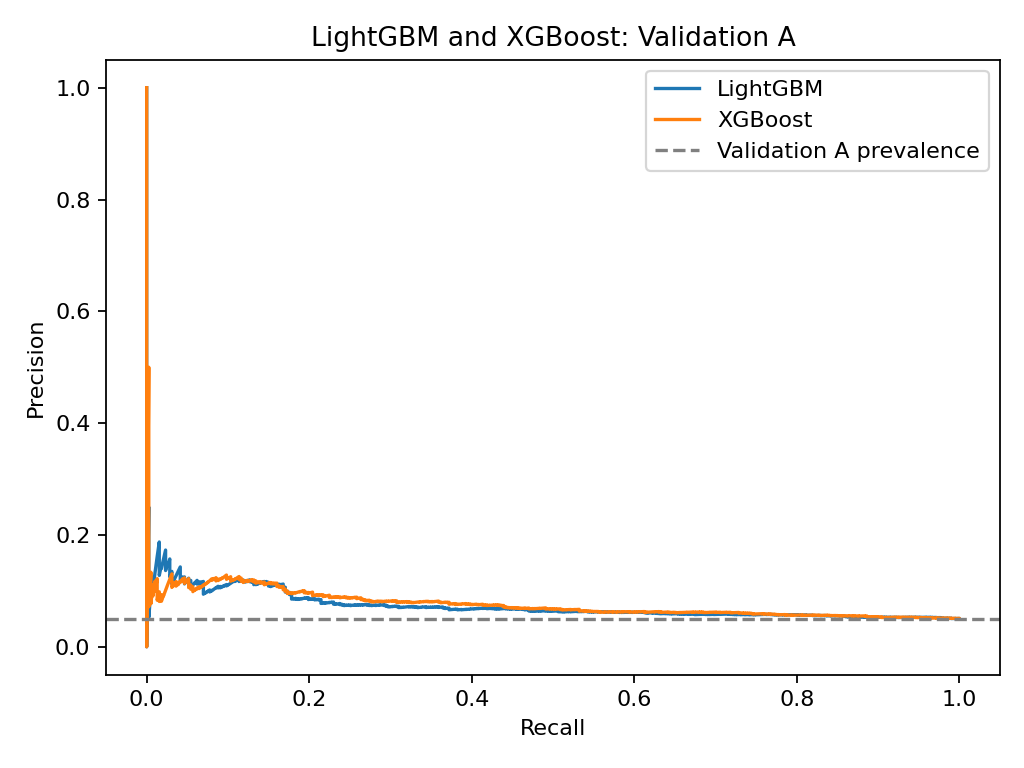

,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,LightGBM,validation_a,raw,7661,387,0.050516,0.073623,0.582513,0.048189,0.201357
1,XGBoost,validation_a,raw,7661,387,0.050516,0.076845,0.596653,0.047978,0.199795


Results: C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\tables\ml_lightgbm_xgboost\20261111_145217_850412
Only Train fitted and Validation A scored; B/Test not scored.


In [15]:
fig, ax = plt.subplots()
for model_name, group in validation_predictions.groupby("model", sort=False):
    precision, recall, _ = precision_recall_curve(group.y_true, group.probability)
    ax.plot(recall, precision, label=model_name)
ax.axhline(float(val.is_late.mean()), linestyle="--", color="gray", label="Validation A prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="LightGBM and XGBoost: Validation A")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "validation_a_pr_curve.png", dpi=160)
display(Image(filename=str(figures / "validation_a_pr_curve.png")))
plt.close(fig)
display(metrics)
print("Results:", tables)
print("Only Train fitted and Validation A scored; B/Test not scored.")
